# G League Exploration

G League (D-League before 2017-18) seasons from 2007-08 to 2025-26. A season combines the regular season and, from 2021-22, the Showcase Cup; playoffs are excluded. G League tables have no possessions or BPM, so counting stats are compared per 36 minutes in both leagues. Basketball-Reference has no G League rate stats (usage, AST%, TRB%, etc.) for 2015-16 or for some players in other seasons; those are left out of the rate-stat comparisons.

**Linking:** Basketball-Reference G League ids look like NBA ids with a trailing 'd' but are assigned separately. A G League player is linked to an NBA player when (1) the id without the 'd' has the same name, or (2) exactly one NBA player has that name; in both cases the NBA career must come within four seasons of the G League season.

**Translation:** a G League season (300+ minutes) paired with the same player's next NBA season (250+ minutes). Averages and correlations are weighted by the harmonic mean of the two seasons' minutes.

**Model tests:** the season-projection model ([07_season_projections](07_season_projections.ipynb)) with and without the prior season's G League stats (walk-forward, 2013-14 to 2025-26), and the rookie model ([06_rookie_projections](06_rookie_projections.ipynb)) with and without the last G League season before the NBA debut (leave-one-class-out). G League features: minutes, points per 36, TS%, usage, AST%, TRB%, PER and WS/48.

Source: Basketball-Reference (G League totals and advanced tables; NBA per-game and advanced tables).

In [1]:
import pandas as pd
import plotly.io as pio

from nba_analytics.players.gleague import (gleague_dataset, gleague_experience, link_report,
                                           projection_test, rookie_test, translation_pairs,
                                           translation_table)
from nba_analytics.players.gleague_plots import (plot_experience, plot_feature_test,
                                                 plot_translation_r, plot_translation_scatter)

# Interactive in JupyterLab / VS Code; static PNG fallback where Plotly can't run (e.g. GitHub)
pio.renderers.default = "plotly_mimetype+png"
pio.renderers["png"].scale = 0.7
pd.set_option("display.max_rows", 100)

gl, nba = gleague_dataset(2008, 2026)

## Linking G League and NBA players

In [2]:
link_report(gl).T.rename(columns={0: "Count"})

,Count
G League players,3830
Linked by id and name,1217
Linked by name and career window,177
No NBA match,2436


## The G League pathway

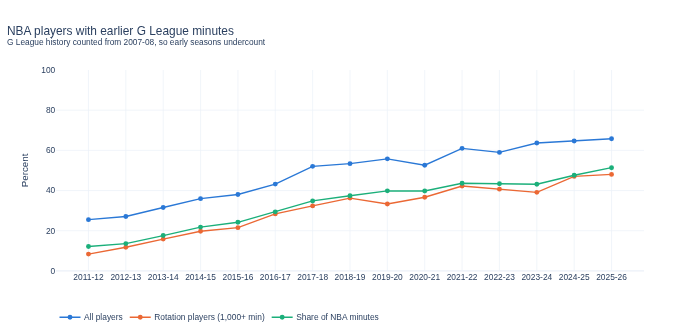

In [3]:
plot_experience(gleague_experience(gl, nba, first=2012)).show()

## G League → next NBA season

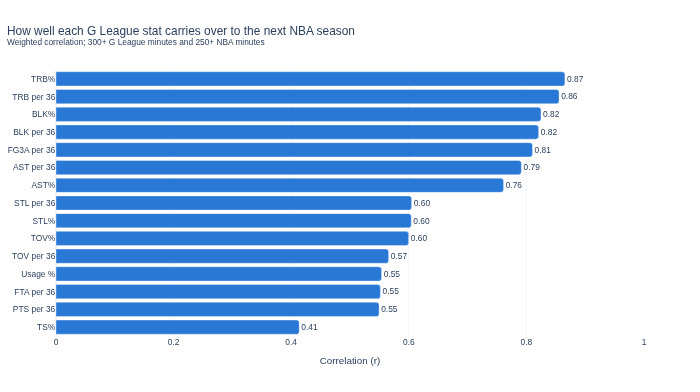

In [4]:
pairs = translation_pairs(gl, nba, lag=1)
table = translation_table(pairs)
plot_translation_r(table).show()

In [5]:
table.set_index("stat").round(3)

,G League,NBA,NBA / G League,r,n
stat,,,,,
PTS per 36,19.895,13.484,0.678,0.549,460
TRB per 36,7.292,6.198,0.850,0.856,460
AST per 36,3.718,3.106,0.835,0.791,460
STL per 36,1.405,1.185,0.843,0.605,460
BLK per 36,0.921,0.705,0.766,0.821,460
TOV per 36,2.693,1.792,0.665,0.566,460
FG3A per 36,5.084,4.431,0.872,0.810,460
FTA per 36,3.713,2.668,0.719,0.552,460
TS%,59.133,54.374,0.920,0.414,460


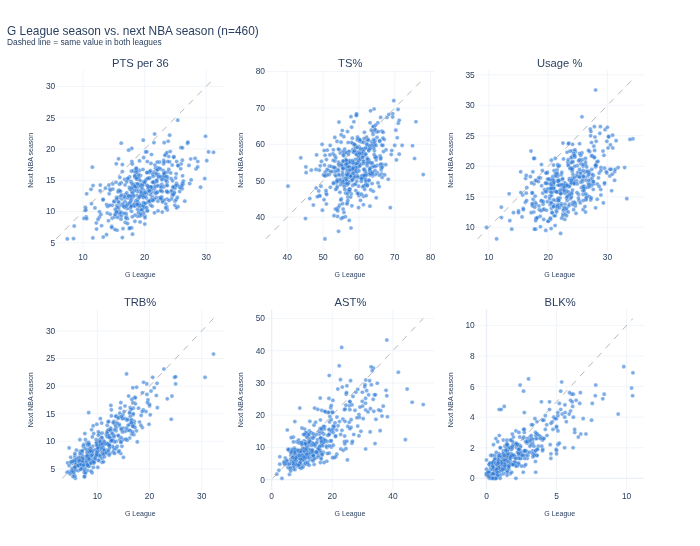

In [6]:
plot_translation_scatter(pairs, ["pts_per_36", "ts_pct", "usg_pct", "trb_pct",
                                  "ast_pct", "blk_pct"]).show()

## Does G League data improve the projection models?

### Season projections

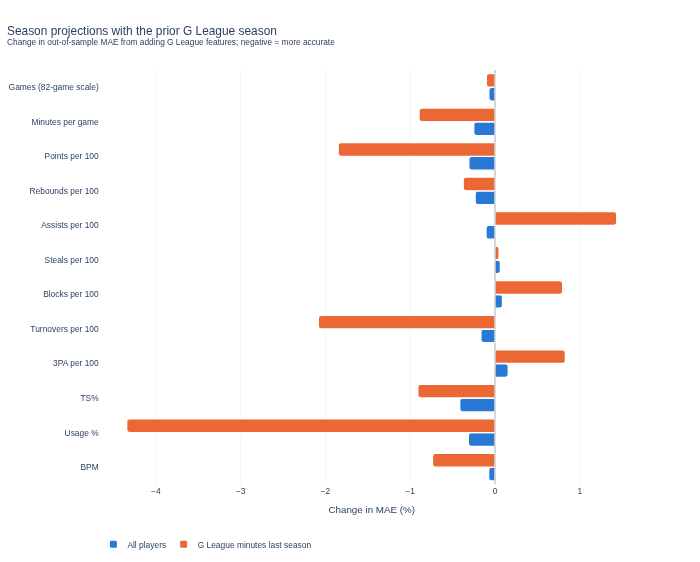

In [7]:
season_test = projection_test(gl)  # two walk-forward runs, ~18 minutes
plot_feature_test(season_test, "Season projections with the prior G League season").show()

In [8]:
season_test.pivot(index="target", columns="group",
                  values=["without", "with G League", "change %", "n"]).round(3)

without                              with G League  \
group                 All players G League minutes last season   All players   
target                                                                         
3PA per 100                 1.156                        1.355         1.158   
Assists per 100             0.879                        0.983         0.878   
BPM                         1.257                        1.445         1.257   
Blocks per 100              0.248                        0.295         0.248   
Games (82-game scale)      15.264                       18.220        15.253   
Minutes per game            4.135                        5.402         4.124   
Points per 100              2.587                        2.709         2.579   
Rebounds per 100            0.998                        1.179         0.996   
Steals per 100              0.274                        0.320         0.275   
TS%                         2.760                        3.486         2.749   
Turnovers per 100           0.439                        0.501         0.438   
Usage %                     2.075                        2.186         2.068   

                                                      change %  \
group                 G League minutes last season All players   
target                                                           
3PA per 100                                  1.367       0.157   
Assists per 100                              0.998      -0.107   
BPM                                          1.434      -0.076   
Blocks per 100                               0.297       0.090   
Games (82-game scale)                       18.201      -0.073   
Minutes per game                             5.353      -0.252   
Points per 100                               2.659      -0.309   
Rebounds per 100                             1.175      -0.235   
Steals per 100                               0.320       0.064   
TS%                                          3.455      -0.416   
Turnovers per 100                            0.491      -0.167   
Usage %                                      2.091      -0.314   

                                                             n  \
group                 G League minutes last season All players   
target                                                           
3PA per 100                                  0.831      4200.0   
Assists per 100                              1.437      4200.0   
BPM                                         -0.738      4200.0   
Blocks per 100                               0.799      4200.0   
Games (82-game scale)                       -0.103      5636.0   
Minutes per game                            -0.896      5636.0   
Points per 100                              -1.851      4200.0   
Rebounds per 100                            -0.376      4200.0   
Steals per 100                               0.049      4200.0   
TS%                                         -0.911      4200.0   
Turnovers per 100                           -2.084      4200.0   
Usage %                                     -4.345      4200.0   

                                                    
group                 G League minutes last season  
target                                              
3PA per 100                                  496.0  
Assists per 100                              496.0  
BPM                                          496.0  
Blocks per 100                               496.0  
Games (82-game scale)                       1142.0  
Minutes per game                            1142.0  
Points per 100                               496.0  
Rebounds per 100                             496.0  
Steals per 100                               496.0  
TS%                                          496.0  
Turnovers per 100                            496.0  
Usage %                                      496.0

### Rookie projections

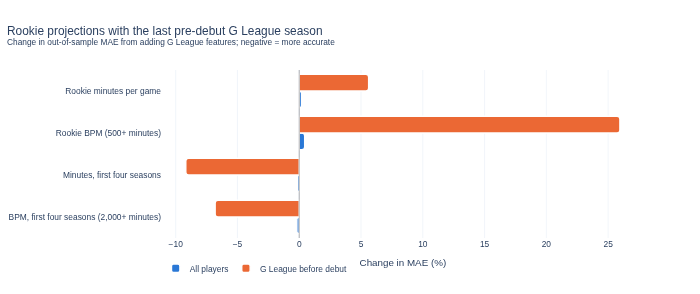

In [9]:
rookies = rookie_test(gl)
plot_feature_test(rookies, "Rookie projections with the last pre-debut G League season").show()

In [10]:
rookies.pivot(index="target", columns="group",
              values=["without", "with G League", "change %", "n"]).round(3)

without                        \
group                                    All players G League before debut   
target                                                                       
BPM, first four seasons (2,000+ minutes)       1.307                 1.097   
Minutes, first four seasons                 1588.439              1250.725   
Rookie BPM (500+ minutes)                      1.422                 1.047   
Rookie minutes per game                        5.723                 6.431   

                                         with G League                        \
group                                      All players G League before debut   
target                                                                         
BPM, first four seasons (2,000+ minutes)         1.305                 1.023   
Minutes, first four seasons                   1585.924              1135.915   
Rookie BPM (500+ minutes)                        1.428                 1.318   
Rookie minutes per game                          5.734                 6.792   

                                            change %                        \
group                                    All players G League before debut   
target                                                                       
BPM, first four seasons (2,000+ minutes)      -0.190                -6.804   
Minutes, first four seasons                   -0.158                -9.180   
Rookie BPM (500+ minutes)                      0.440                25.951   
Rookie minutes per game                        0.187                 5.615   

                                                   n                        
group                                    All players G League before debut  
target                                                                      
BPM, first four seasons (2,000+ minutes)       441.0                  16.0  
Minutes, first four seasons                    915.0                  73.0  
Rookie BPM (500+ minutes)                      450.0                  14.0  
Rookie minutes per game                       1152.0                  90.0